# Pelatihan Model Analisis Sentimen Ulasan Livin' by Mandiri

## Tentang Notebook
Notebook ini adalah tahap kedua proyek analisis sentimen ulasan aplikasi **Livin' by Mandiri**. Dataset dibaca dari hasil scraping pada notebook pertama, lalu diproses hingga menghasilkan model klasifikasi sentimen tiga kelas (negatif, netral, positif).


## Alur di Notebook Ini
1. Menghubungkan Google Drive dan menyiapkan path
2. Import library
3. Memuat dan mengecek data
4. Preprocessing teks
5. Pelabelan sentimen
6. Eksplorasi data dan penanganan ketidakseimbangan kelas
7. Skema pelatihan 1: Logistic Regression + TF-IDF
8. Skema pelatihan 2: SVM + TF-IDF n-gram
9. Skema pelatihan 3: LSTM + Embedding
10. Inference

## 1. Menghubungkan Google Drive dan Menyiapkan Path
Google Drive dihubungkan (*mount*) agar dataset hasil scraping dapat dibaca di notebook ini, serta untuk menyimpan keluaran proses berikutnya seperti dataset berlabel dan model. Path folder dan file didefinisikan di awal agar mudah diubah dan konsisten digunakan.

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# mengelola path file dan folder
import os

FOLDER = '/content/drive/MyDrive/Colab Notebooks/submission_sentimen_analisis'
PATH_CSV = os.path.join(FOLDER, 'ulasan_aplikasi_livin.csv')

print('Data   :', PATH_CSV)
print('Ada?   :', os.path.exists(PATH_CSV))

Data   : /content/drive/MyDrive/Colab Notebooks/submission_sentimen_analisis/ulasan_aplikasi_livin.csv
Ada?   : True


## 2. Import Library
Seluruh library yang digunakan di notebook ini di-import di awal agar mudah dilacak dan dicocokkan dengan `requirements.txt`.

- **Pengolahan data dan visualisasi:** `pandas`, `numpy`, `matplotlib`, `wordcloud`
- **Preprocessing teks:** `re`, `string`, `nltk` (tokenisasi dan stopword), `Sastrawi` (stemming bahasa Indonesia)
- **Machine learning klasik:** `scikit-learn` (TF-IDF, pembagian data, model, metrik evaluasi)
- **Deep learning:** `tensorflow`/`keras` (tokenisasi, padding, layer Embedding dan LSTM/GRU)

Nilai `SEED` ditetapkan agar proses acak (pembagian data dan inisialisasi model) menghasilkan hasil yang sama setiap kali notebook dijalankan.

In [ ]:
!pip install Sastrawi wordcloud -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 6.2 MB/s eta 0:00:00


In [ ]:
# =============================================================
# Instalasi dan Import Library
# =============================================================

import re
import string
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Preprocessing teks
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Machine learning klasik
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder

# Deep learning
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

# Data NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Seed agar hasil konsisten
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## 3. Memuat dan Mengecek Data
Dataset hasil scraping (`ulasan_aplikasi_livin.csv`) dibaca dari Google Drive, lalu dicek kondisinya sebelum diproses:
- jumlah baris dan kolom,
- jumlah ulasan duplikat (berdasarkan `reviewId`),
- data kosong pada kolom `content`,
- sebaran rating (`score`), yang nantinya menjadi dasar pelabelan sentimen.

Pengecekan ini penting untuk memastikan jumlah data masih memenuhi target setelah duplikat dan data kosong dibuang pada tahap preprocessing.

In [ ]:
# Membaca dataset hasil scraping
df = pd.read_csv(PATH_CSV)

print('Jumlah baris dan kolom:', df.shape)
df.head()

Jumlah baris dan kolom: (15400, 4)


,reviewId,content,score,at
0,2ad89742-c52e-4f85-bf2b-d054b71ff41c,oh pantes ya ratenya kecil bgt udah makan ruan...,1,2026-10-10 23:24:37
1,a78172d7-3d94-48f3-ab3f-63d424143639,Maintenance berapa lama berhari-hari belum kun...,1,2026-10-10 22:37:49
2,deabe913-dd76-4b3d-bb4d-8d551d3b4284,"gabisa kebuka kalo lagi mau dipake gituloh, ka...",1,2026-10-10 22:29:13
3,ca09a8e1-198a-4035-90a3-ab560dd7886d,Mandiri sistemnya bener bener lambat sekali!!!...,1,2026-10-10 17:12:14
4,62264878-771a-4443-9f45-6e33dd253b8d,ndk bisa di ss payah,1,2026-10-10 17:07:06


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15400 entries, 0 to 15399
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   reviewId  15400 non-null  object
 1   content   15400 non-null  object
 2   score     15400 non-null  int64 
 3   at        15400 non-null  object
dtypes: int64(1), object(3)
memory usage: 481.4+ KB

Ulasan duplikat (reviewId) : 0
Teks ulasan kosong         : 0

Sebaran rating:
score
1    2600
2    2600
3    5000
4    2600
5    2600
Name: count, dtype: int64


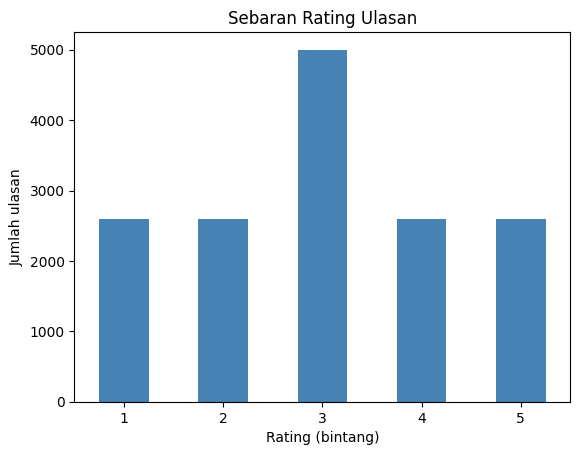

In [ ]:
# Informasi kolom dan tipe data
df.info()

# Jumlah duplikat dan data kosong
print('\nUlasan duplikat (reviewId) :', df['reviewId'].duplicated().sum())
print('Teks ulasan kosong         :', df['content'].isna().sum())

# Sebaran rating
print('\nSebaran rating:')
print(df['score'].value_counts().sort_index())

# Viusalisasi  Sebaran rating
df['score'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Sebaran Rating Ulasan')
plt.xlabel('Rating (bintang)')
plt.ylabel('Jumlah ulasan')
plt.xticks(rotation=0)
plt.show()

## 4. Preprocessing Teks
Ulasan pengguna berisi banyak noise: huruf kapital tidak seragam, tautan, angka, emoji, tanda baca, huruf berulang ("bagusss"), dan singkatan tidak baku ("gk", "udh", "bgt"). Preprocessing bertujuan menyeragamkan teks agar model belajar dari kata yang bermakna, bukan dari variasi penulisan.

Langkah-langkah yang dilakukan, secara berurutan:

| No | Langkah | Tujuan |
|----|---------|--------|
| 1 | Case folding | Menyeragamkan semua huruf menjadi huruf kecil |
| 2 | Pembersihan karakter | Menghapus tautan, angka, emoji, dan tanda baca |
| 3 | Normalisasi huruf berulang | Menyatukan variasi seperti "bagusss" menjadi "bagus" |
| 4 | Normalisasi slang | Mengubah singkatan tidak baku menjadi bentuk baku |
| 5 | Tokenisasi | Memecah teks menjadi daftar kata |
| 6 | Penghapusan stopword | Membuang kata umum, dengan kata negasi dipertahankan |
| 7 | Stemming | Mengubah kata berimbuhan menjadi kata dasar |
| 8 | Pembersihan akhir | Membuang baris kosong dan teks duplikat |

Satu hasil preprocessing yang sama digunakan untuk ketiga skema pelatihan, agar perbedaan akurasi antar skema berasal dari algoritma, fitur, dan pembagian data, bukan dari perbedaan cara membersihkan teks.

### 4.1 Case Folding
Seluruh huruf diubah menjadi huruf kecil agar kata seperti "Bagus", "BAGUS", dan "bagus" dihitung sebagai satu kata. Langkah ini dilakukan paling awal karena daftar stopword dan kamus slang ditulis dalam huruf kecil.

### 4.2 Pembersihan Karakter
Tautan dihapus, lalu semua karakter selain huruf (angka, emoji, dan tanda baca) diganti dengan spasi. Diganti spasi, bukan dihapus, agar kata yang menempel tidak menyatu.

**Keputusan:**
- **Angka** dihapus karena pada ulasan aplikasi perbankan umumnya berupa kode error, nominal, atau nomor, yang jarang membawa sentimen.
- **Emoji** dihapus. Emoji ditemukan pada sekitar 6,5% ulasan dan tersebar merata di semua rating, sehingga keberadaannya tidak membedakan sentimen. Keputusan ini dicatat sebagai keterbatasan, karena beberapa emoji (misalnya jempol atau wajah marah) sebenarnya dapat membawa sentimen.

In [ ]:
# Mengubah semua karakter dalam teks menjadi huruf kecil
def casefoldingText(text):
  text = text.lower()
  return text

def cleaningText(text):
    text = re.sub(r"http\S+", ' ', text)         # menghapus link
    text = re.sub(r'@[A-Za-z0-9]+', ' ', text)   # menghapus mention
    text = re.sub(r'#[A-Za-z0-9]+', ' ', text)   # menghapus hashtag
    text = re.sub(r'[0-9]+', ' ', text)          # menghapus angka
    text = re.sub(r'[^\w\s]', ' ', text)         # menghapus emoji dan tanda baca
    text = text.replace('_', ' ')                # underscore termasuk \w, jadi dihapus terpisah
    text = re.sub(r'\s+', ' ', text).strip()     # merapikan spasi dan baris baru
    return text

### 4.3 Normalisasi Huruf Berulang
Huruf yang berulang lebih dari dua kali dipadatkan, misalnya "bagusss" menjadi "bagus" dan "lambatttt" menjadi "lambat". Tanpa langkah ini, variasi penulisan dianggap kata yang berbeda dan hitungan kata menjadi terpecah.

### 4.4 Normalisasi Slang
Singkatan dan bentuk tidak baku diubah menjadi bentuk baku menggunakan kamus (misalnya "gk" menjadi "tidak", "udh" menjadi "sudah", "bgt" menjadi "banget"). Langkah ini dilakukan sebelum penghapusan stopword agar kata yang baru dibakukan dapat dikenali dengan benar.

In [ ]:
def normalisasiHurufBerulang(text):
    # Tiga huruf sama atau lebih dipadatkan jadi satu: "bagusss" -> "bagus"
    return re.sub(r'(.)\1{2,}', r'\1', text)

slangwords = {
    # negasi, jadikan satu bentuk supaya model melihat satu kata
    "gk": "tidak", "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak",
    "enggak": "tidak", "engga": "tidak", "tdk": "tidak", "gada": "tidak ada",
    "gabisa": "tidak bisa", "gbs": "tidak bisa", "blm": "belum", "belom": "belum",
    # umum
    "udh": "sudah", "udah": "sudah", "sdh": "sudah", "dah": "sudah",
    "yg": "yang", "dgn": "dengan", "krn": "karena", "karna": "karena",
    "tp": "tapi", "tpi": "tapi", "jd": "jadi", "sy": "saya", "sm": "sama",
    "utk": "untuk", "dr": "dari", "pd": "pada", "klo": "kalau", "kalo": "kalau",
    "lg": "lagi", "bs": "bisa", "gmn": "bagaimana", "gimana": "bagaimana",
    "emg": "memang", "skrg": "sekarang", "bgt": "banget", "bngt": "banget",
    "mantapp": "mantap", "jelekk": "jelek",
    # konteks aplikasi
    "apk": "aplikasi", "apl": "aplikasi", "trx": "transaksi", "trf": "transfer",
    "tf": "transfer", "lemot": "lambat", "mf": "maaf",
    "makasih": "terima kasih", "trims": "terima kasih", "thanks": "terima kasih",
}

def fix_slangwords(text):
    kata = text.split()
    return ' '.join(slangwords.get(k, k) for k in kata)

### 4.5 Tokenisasi
Teks dipecah menjadi daftar kata (token) agar setiap kata dapat diperiksa dan diproses satu per satu pada langkah berikutnya.

### 4.6 Penghapusan Stopword
Kata umum yang tidak membawa makna (seperti "yang", "dan", "di") dibuang menggunakan daftar stopword bahasa Indonesia dan bahasa Inggris dari NLTK, ditambah beberapa kata tidak baku yang sering muncul.

**Kata negasi tetap dipertahankan** ("tidak", "bukan", "belum", "tak", "jangan", "tanpa"). Kata-kata ini ada di daftar stopword bawaan, tetapi membuangnya dapat membalik makna kalimat: "tidak murah" menjadi "murah". Hal ini ditemukan pada eksperimen awal dengan data lain, ketika sebuah kalimat negatif terklasifikasi sebagai positif akibat negasi yang terbuang.

In [ ]:
# Daftar stopword dibuat sekali di luar fungsi (jauh lebih cepat)
listStopwords = set(stopwords.words('indonesian'))
listStopwords.update(stopwords.words('english'))
listStopwords.update(['nya', 'na', 'sih', 'ku', 'di', 'ya', 'loh', 'kah', 'woi', 'woy'])
# Kata negasi dipertahankan (tidak dianggap stopword)
negasi = ['tidak', 'bukan', 'belum', 'tak', 'jangan', 'tanpa', 'kurang',
          'not', 'no', 'never']
listStopwords.difference_update(negasi + ['bisa'])

def tokenizingText(text):
    return word_tokenize(text)

def filteringText(tokens):
    return [t for t in tokens if t not in listStopwords]

In [ ]:
slangwords.update({
    "ndk": "tidak", "nda": "tidak", "ndak": "tidak", "gx": "tidak",
    "jg": "juga", "dpt": "dapat", "dapet": "dapat",
    "pake": "pakai", "dipake": "dipakai", "bener": "benar",
})

In [ ]:
df['teks_bersih'] = (df['content']
                     .apply(casefoldingText)
                     .apply(cleaningText)
                     .apply(normalisasiHurufBerulang)
                     .apply(fix_slangwords))
df['token'] = df['teks_bersih'].apply(tokenizingText).apply(filteringText)

print('Teks kosong setelah dibersihkan:', (df['token'].str.len() == 0).sum())
df[['content', 'teks_bersih', 'token']].head(10)

Teks kosong setelah dibersihkan: 263


,content,teks_bersih,token
0,oh pantes ya ratenya kecil bgt udah makan ruan...,oh pantes ya ratenya kecil banget sudah makan ...,"[oh, pantes, ratenya, banget, makan, ruang, sa..."
1,Maintenance berapa lama berhari-hari belum kun...,maintenance berapa lama berhari hari belum kun...,"[maintenance, berhari, belum, kunjung, sembuh]"
2,"gabisa kebuka kalo lagi mau dipake gituloh, ka...",tidak bisa kebuka kalau lagi mau dipakai gitul...,"[tidak, bisa, kebuka, dipakai, gituloh]"
3,Mandiri sistemnya bener bener lambat sekali!!!...,mandiri sistemnya benar benar lambat sekali ke...,"[mandiri, sistemnya, lambat, kecewa, saudara, ..."
4,ndk bisa di ss payah,tidak bisa di ss payah,"[tidak, bisa, ss, payah]"
5,gangguan terus,gangguan terus,[gangguan]
6,harus di update terus bikin pusing puguh hp gu...,harus di update terus bikin pusing puguh hp gu...,"[update, bikin, pusing, puguh, hp, gue, kentang]"
7,mandiri bank ga jelas saldo gua ga bisa di tar...,mandiri bank tidak jelas saldo gua tidak bisa ...,"[mandiri, bank, tidak, saldo, gua, tidak, bisa..."
8,"sering gangguan,GK bisa d buka admin bulanan j...",sering gangguan tidak bisa d buka admin bulana...,"[gangguan, tidak, bisa, buka, admin, bulanan]"
9,"Transaksi 100rb dpt poin 1, transaksi 900rb dp...",transaksi rb dapat poin transaksi rb dapat poi...,"[transaksi, rb, poin, transaksi, rb, poin, poi..."


### 4.7 Stemming
Kata berimbuhan diubah menjadi kata dasar menggunakan **Sastrawi**, library stemming bahasa Indonesia yang mencocokkan hasil dengan kamus kata dasar, sehingga keluarannya berupa kata yang valid (misalnya "pertumbuhan" menjadi "tumbuh"). Stemming mengurangi variasi kata sehingga kosakata lebih ringkas.

Karena stemming dapat mengubah makna pada kata tertentu, hasilnya diuji terlebih dahulu pada kata-kata yang sering muncul di ulasan. [Isi hasil pengujian di sini.] Proses dipercepat dengan menyimpan hasil stemming per kata unik (*cache*), sehingga setiap kata hanya diproses sekali.

### 4.8 Pembersihan Akhir
Setelah semua tahap, baris yang teksnya menjadi kosong (misalnya ulasan yang hanya berisi emoji atau angka) dan baris dengan teks hasil preprocessing yang sama persis dibuang. Jumlah data sebelum dan sesudah dicatat untuk memastikan syarat jumlah data minimal masih terpenuhi, dan sebaran kelas dicek kembali.

In [ ]:
stemmer = StemmerFactory().create_stemmer()

pengecualian = {
    'perbaiki': 'perbaiki', 'diperbaiki': 'perbaiki',
    'memperbaiki': 'perbaiki', 'perbaikan': 'perbaiki',
    'berhasil': 'berhasil', 'memuaskan': 'puas',
    'tidak': 'tidak', 'bukan': 'bukan', 'belum': 'belum', 'tak': 'tak',
    'jangan': 'jangan', 'tanpa': 'tanpa', 'kurang': 'kurang',
}

cache = {}
def stem_kata(w):
    if w in pengecualian:
        return pengecualian[w]
    if w not in cache:
        cache[w] = stemmer.stem(w)
    return cache[w]

In [ ]:
df['token_stem'] = df['token'].apply(lambda toks: [stem_kata(w) for w in toks])
df['teks_akhir'] = df['token_stem'].apply(' '.join)

df[['content', 'teks_akhir']].sample(8, random_state=42)

,content,teks_akhir
411,lemot.... lelet,lambat lelet
5076,gk bisa tranfer,tidak bisa tranfer
8146,"sering ganti sandi, jadi suka lupa",ganti sandi suka lupa
8304,bagus,bagus
4147,terkait kode RPT 02 kenapa prosesnya lama skal...,kait kode rpt proses skali bolak bank tidak ha...
14366,bermanfaat,manfaat
2608,kenapa engga bisa masuk livin pak,tidak bisa masuk livin
5279,Tolong jgn sering update,tolong jgn update


In [ ]:
n_awal = len(df)

df_final = df[df['teks_akhir'].str.strip() != ''].copy()
n_setelah_kosong = len(df_final)

df_final = df_final.drop_duplicates(subset='teks_akhir').copy()
n_akhir = len(df_final)

print('Awal                  :', n_awal)
print('Setelah buang kosong  :', n_setelah_kosong)
print('Setelah buang duplikat:', n_akhir)
print('Syarat 10.000 terpenuhi:', n_akhir >= 10000)
print(df_final['score'].value_counts().sort_index())

Awal                  : 15400
Setelah buang kosong  : 15130
Setelah buang duplikat: 12576
Syarat 10.000 terpenuhi: True
score
1    2326
2    2465
3    4568
4    1889
5    1328
Name: count, dtype: int64


In [ ]:
# Simpan data final ke google drive supaya tidak perlu rerun proses steming
df_final.to_csv('/content/drive/MyDrive/Colab Notebooks/ulasan_preprocessed.csv', index=False)

## 5. Pelabelan Sentimen
Label sentimen dibuat dari **rating bintang** yang diberikan pengguna, menjadi dua kelas:

| Rating | Label |
|--------|-------|
| 1 dan 2 | negatif |
| 5 | positif |
| 3 dan 4 | dibuang |

Rating dipilih karena diberikan langsung oleh penulis ulasan, sehingga lebih konsisten dengan isi teks dibanding pelabelan berbasis kamus kata. Rating 3 dan 4 dibuang karena umumnya berisi campuran pujian dan keluhan sehingga sentimennya ambigu.

**Keterbatasan:**
- Model dilatih hanya pada ulasan dengan sentimen yang jelas, sehingga mungkin kurang akurat pada ulasan campuran di dunia nyata.
- Kelas tidak seimbang (negatif jauh lebih banyak), sehingga evaluasi menggunakan macro F1 dan metrik per kelas, tidak hanya akurasi.
- Rating dapat tidak sejalan dengan isi ulasan (misalnya bintang 5 dengan isi keluhan).

Jumlah data: 6119
label
negatif    4791
positif    1328
Name: count, dtype: int64


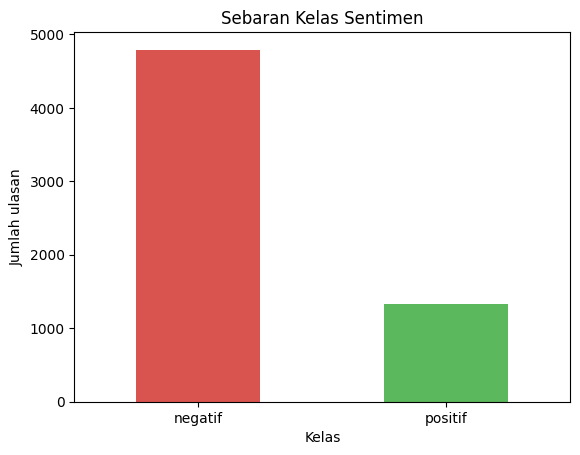

In [ ]:
# Mengambil ulasan bintang 1, 2, dan 5, lalu memberi label sentimen
df_model = df_final[df_final['score'].isin([1, 2, 5])].copy()
df_model['label'] = np.where(df_model['score'] <= 2, 'negatif', 'positif')

print('Jumlah data:', len(df_model))
print(df_model['label'].value_counts())

df_model['label'].value_counts().plot(kind='bar', color=['#d9534f', '#5cb85c'])
plt.title('Sebaran Kelas Sentimen')
plt.xlabel('Kelas')
plt.ylabel('Jumlah ulasan')
plt.xticks(rotation=0)
plt.show()

## **Ketidakseimbangan Kelas**
Sebaran kelas pada data tidak seimbang: ulasan negatif sekitar 78% dan ulasan positif sekitar 22%. Jika dibiarkan, model cenderung memprediksi kelas mayoritas karena itu sudah memberi akurasi yang tampak tinggi.

Ketidakseimbangan ditangani dengan **pembobotan kelas** (`class_weight='balanced'`) pada proses pelatihan, yaitu kesalahan pada kelas minoritas diberi bobot lebih besar. Cara ini dipilih karena tidak mengubah atau menghapus data (jumlah data tetap memenuhi syarat) dan tidak berisiko menggandakan baris yang sama ke data latih dan data uji. Pembobotan hanya berlaku saat pelatihan dan dihitung dari data latih di tiap skema. **Data uji tidak diubah** agar evaluasi mencerminkan kondisi nyata.

Karena kelas tidak seimbang, evaluasi memakai akurasi **bersama** macro F1 dan metrik per kelas (precision, recall, F1).

## 6. Eksplorasi Data dan Penanganan Ketidakseimbangan Kelas

### 6.1 Eksplorasi Kata
Kata yang paling sering muncul pada tiap kelas divisualisasikan dengan word cloud untuk memastikan hasil preprocessing wajar dan melihat perbedaan topik antara ulasan positif dan negatif.



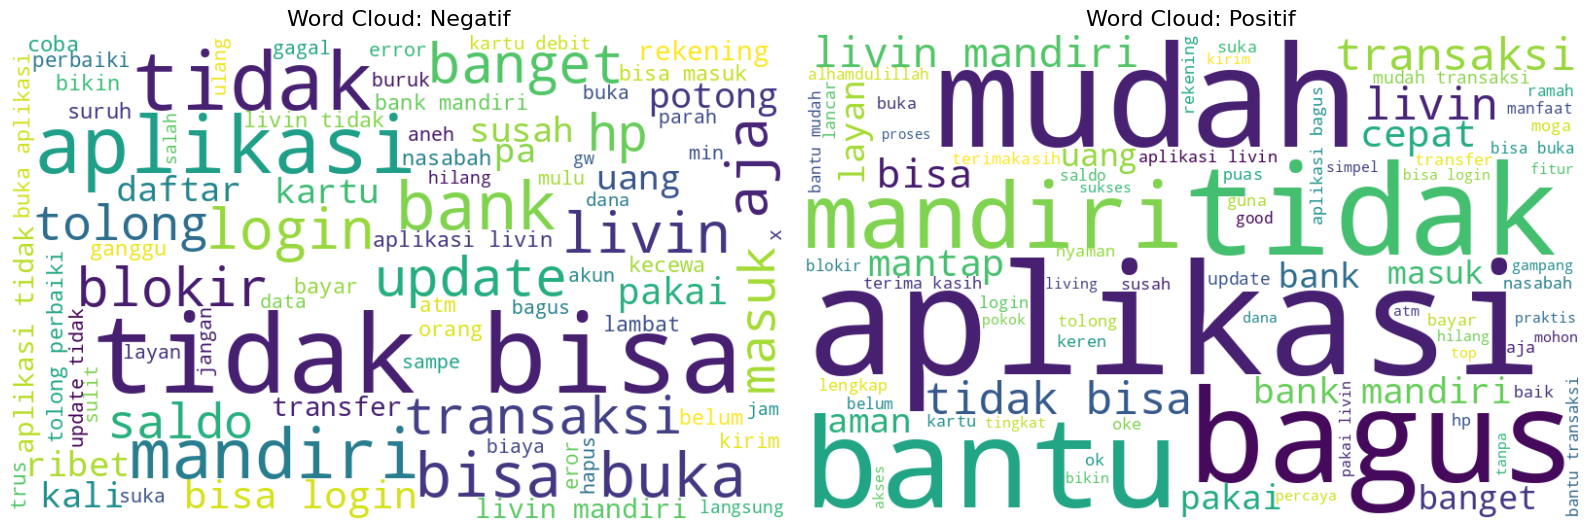

In [ ]:
teks_neg = ' '.join(df_model[df_model['label'] == 'negatif']['teks_akhir'])
teks_pos = ' '.join(df_model[df_model['label'] == 'positif']['teks_akhir'])

wc_neg = WordCloud(width=800, height=500, background_color='white',
                   max_words=80, random_state=SEED).generate(teks_neg)
wc_pos = WordCloud(width=800, height=500, background_color='white',
                   max_words=80, random_state=SEED).generate(teks_pos)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(wc_neg, interpolation='bilinear')
axes[0].set_title('Word Cloud: Negatif', fontsize=16)
axes[0].axis('off')
axes[1].imshow(wc_pos, interpolation='bilinear')
axes[1].set_title('Word Cloud: Positif', fontsize=16)
axes[1].axis('off')
plt.tight_layout()
plt.show()

## 7. Skema Pelatihan 1: Logistic Regression + TF-IDF

| Komponen | Pilihan |
|----------|---------|
| Algoritma | Logistic Regression |
| Ekstraksi fitur | TF-IDF (kata tunggal) |
| Pembagian data | 80% latih, 20% uji |

Skema ini menjadi model dasar (*baseline*): sederhana, cepat dilatih, dan hasilnya mudah dijelaskan. Data dibagi secara *stratified* agar proporsi kelas positif dan negatif sama di data latih dan data uji.

In [ ]:
hasil_skema = {}

In [ ]:
X = df_model['teks_akhir']
y = df_model['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print('Data latih:', len(X_train), '| Data uji:', len(X_test))
print('\nProporsi data latih:\n', y_train.value_counts(normalize=True).round(3))
print('\nProporsi data uji:\n', y_test.value_counts(normalize=True).round(3))

Data latih: 4895 | Data uji: 1224

Proporsi data latih:
 label
negatif    0.783
positif    0.217
Name: proportion, dtype: float64

Proporsi data uji:
 label
negatif    0.783
positif    0.217
Name: proportion, dtype: float64


### 7.1 Ekstraksi Fitur dengan TF-IDF
Teks diubah menjadi angka dengan TF-IDF, yaitu bobot kata yang tinggi untuk kata yang sering muncul di sebuah ulasan tetapi jarang muncul di ulasan lain. Kamus kata hanya dibuat dari **data latih** (`fit`), kemudian diterapkan ke data uji (`transform`) agar tidak ada informasi data uji yang bocor ke proses pelatihan. Kata yang muncul di kurang dari 2 ulasan diabaikan (`min_df=2`) untuk mengurangi kata langka dan salah ketik.

In [ ]:
tfidf_s1 = TfidfVectorizer(ngram_range=(1, 1), min_df=2)

X_train_tfidf = tfidf_s1.fit_transform(X_train)   # kamus dibuat dari data latih
X_test_tfidf = tfidf_s1.transform(X_test)         # data uji hanya diterapkan

print('Ukuran kamus:', len(tfidf_s1.vocabulary_))
print('Bentuk matriks latih:', X_train_tfidf.shape)
print('Bentuk matriks uji  :', X_test_tfidf.shape)

Ukuran kamus: 1925
Bentuk matriks latih: (4895, 1925)
Bentuk matriks uji  : (1224, 1925)


### 7.2 Pelatihan dan Evaluasi
Model dilatih dengan Logistic Regression. Karena kelas tidak seimbang (negatif sekitar 78%), digunakan pembobotan kelas (`class_weight='balanced'`) sehingga kesalahan pada kelas positif (minoritas) diberi bobot lebih besar. Pembobotan hanya berlaku saat pelatihan, data uji tidak diubah.

Evaluasi memakai akurasi pada data latih dan data uji, macro F1, serta metrik per kelas. Selisih akurasi latih dan uji dipakai untuk mendeteksi *overfitting*.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

Akurasi latih : 0.9083
Akurasi uji   : 0.8595
Macro F1 uji  : 0.8097

Laporan klasifikasi (data uji):
              precision    recall  f1-score   support

     negatif      0.941     0.876     0.907       958
     positif      0.642     0.801     0.712       266

    accuracy                          0.859      1224
   macro avg      0.791     0.838     0.810      1224
weighted avg      0.876     0.859     0.865      1224



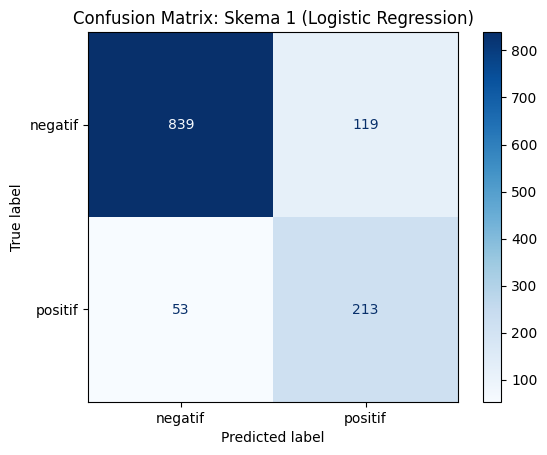

In [ ]:
lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED)
lr.fit(X_train_tfidf, y_train)

pred_train = lr.predict(X_train_tfidf)
pred_test = lr.predict(X_test_tfidf)

acc_train = accuracy_score(y_train, pred_train)
acc_test = accuracy_score(y_test, pred_test)
f1_test = f1_score(y_test, pred_test, average='macro')

print(f'Akurasi latih : {acc_train:.4f}')
print(f'Akurasi uji   : {acc_test:.4f}')
print(f'Macro F1 uji  : {f1_test:.4f}')
print('\nLaporan klasifikasi (data uji):')
print(classification_report(y_test, pred_test, digits=3))

hasil_skema['Skema 1'] = {'train': acc_train, 'test': acc_test, 'macro_f1': f1_test}

ConfusionMatrixDisplay.from_predictions(y_test, pred_test, cmap='Blues')
plt.title('Confusion Matrix: Skema 1 (Logistic Regression)')
plt.show()

Logistic Regression dengan TF-IDF mencapai akurasi uji 0,8595 dan macro F1 0,81. Model lebih baik dalam mengenali kelas negatif (F1 0,91) daripada kelas positif (F1 0,71). Selisih akurasi latih (0,908) dan uji (0,860) menunjukkan overfitting ringan.

## 8. Skema Pelatihan 2: SVM + TF-IDF (n-gram)

| Komponen | Pilihan |
|----------|---------|
| Algoritma | Support Vector Machine (Linear SVC) |
| Ekstraksi fitur | TF-IDF dengan n-gram 1 sampai 2 (kata tunggal dan pasangan dua kata) |
| Pembagian data | 70% latih, 30% uji |

Dibandingkan skema 1, skema ini mengubah tiga hal sekaligus: algoritma (SVM), ekstraksi fitur (ditambah n-gram) dan pembagian data (data uji lebih besar). N-gram dipakai agar sebagian urutan kata tertangkap, misalnya "tidak bisa" menjadi satu fitur sendiri, bukan dua kata terpisah.

In [ ]:
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(
    df_model['teks_akhir'], df_model['label'],
    test_size=0.3, random_state=SEED, stratify=df_model['label']
)

print('Data latih:', len(X_train_s2), '| Data uji:', len(X_test_s2))
print('\nProporsi data latih:\n', y_train_s2.value_counts(normalize=True).round(3))
print('\nProporsi data uji:\n', y_test_s2.value_counts(normalize=True).round(3))

Data latih: 4283 | Data uji: 1836

Proporsi data latih:
 label
negatif    0.783
positif    0.217
Name: proportion, dtype: float64

Proporsi data uji:
 label
negatif    0.783
positif    0.217
Name: proportion, dtype: float64


### 8.1 Ekstraksi Fitur dengan TF-IDF n-gram
Kamus fitur dibuat dari kata tunggal dan pasangan dua kata (`ngram_range=(1, 2)`), hanya dari **data latih**. Pasangan kata yang muncul di kurang dari 2 ulasan diabaikan (`min_df=2`) agar jumlah fitur tidak membengkak.

In [ ]:
tfidf_s2 = TfidfVectorizer(ngram_range=(1, 2), min_df=2)

X_train_s2_tfidf = tfidf_s2.fit_transform(X_train_s2)
X_test_s2_tfidf = tfidf_s2.transform(X_test_s2)

print('Ukuran kamus:', len(tfidf_s2.vocabulary_))
print('Bentuk matriks latih:', X_train_s2_tfidf.shape)
print('Bentuk matriks uji  :', X_test_s2_tfidf.shape)

Ukuran kamus: 5078
Bentuk matriks latih: (4283, 5078)
Bentuk matriks uji  : (1836, 5078)


### 8.2 Pelatihan dan Evaluasi
Model SVM dilatih dengan kernel linear (`LinearSVC`), yang cocok untuk data teks berdimensi besar dan cepat dilatih. Ketidakseimbangan kelas ditangani dengan `class_weight='balanced'`. Evaluasi memakai akurasi latih dan uji, macro F1, dan metrik per kelas.

Akurasi latih : 0.9680
Akurasi uji   : 0.8742
Macro F1 uji  : 0.8216

Laporan klasifikasi (data uji):
              precision    recall  f1-score   support

     negatif      0.933     0.905     0.918      1438
     positif      0.689     0.764     0.725       398

    accuracy                          0.874      1836
   macro avg      0.811     0.834     0.822      1836
weighted avg      0.880     0.874     0.876      1836



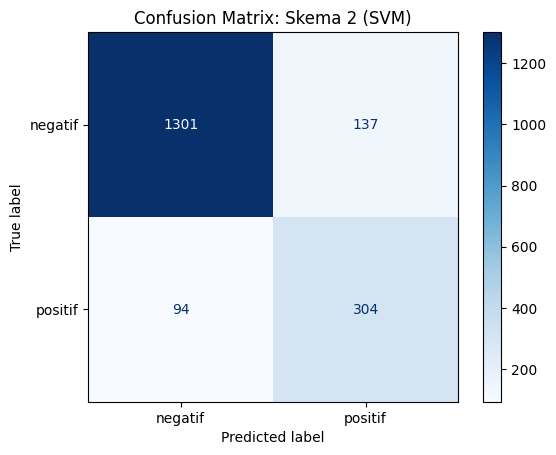

In [ ]:
svm = LinearSVC(class_weight='balanced', max_iter=5000, random_state=SEED)
svm.fit(X_train_s2_tfidf, y_train_s2)

pred_train_s2 = svm.predict(X_train_s2_tfidf)
pred_test_s2 = svm.predict(X_test_s2_tfidf)

acc_train_s2 = accuracy_score(y_train_s2, pred_train_s2)
acc_test_s2 = accuracy_score(y_test_s2, pred_test_s2)
f1_test_s2 = f1_score(y_test_s2, pred_test_s2, average='macro')

print(f'Akurasi latih : {acc_train_s2:.4f}')
print(f'Akurasi uji   : {acc_test_s2:.4f}')
print(f'Macro F1 uji  : {f1_test_s2:.4f}')
print('\nLaporan klasifikasi (data uji):')
print(classification_report(y_test_s2, pred_test_s2, digits=3))

hasil_skema['Skema 2'] = {'train': acc_train_s2, 'test': acc_test_s2, 'macro_f1': f1_test_s2}

ConfusionMatrixDisplay.from_predictions(y_test_s2, pred_test_s2, cmap='Blues')
plt.title('Confusion Matrix: Skema 2 (SVM)')
plt.show()

SVM dengan TF-IDF n-gram mencapai akurasi uji 0,8742 dan macro F1 0,8216. Model lebih baik mengenali kelas negatif (F1 0,918) daripada kelas positif (F1 0,725), dengan precision positif 0,689. Selisih akurasi latih (0,968) dan uji (0,874) menunjukkan overfitting yang lebih besar dibanding skema 1, kemungkinan akibat jumlah fitur yang lebih banyak dari n-gram.

## 9. Skema Pelatihan 3: LSTM + Embedding

| Komponen | Pilihan |
|----------|---------|
| Algoritma | LSTM (deep learning) |
| Ekstraksi fitur | Embedding (dipelajari bersama model) |
| Pembagian data | 80% latih (10% di antaranya untuk validasi), 20% uji |

Berbeda dengan skema 1 dan 2 yang hanya menghitung kata, LSTM membaca ulasan **berurutan** sehingga urutan kata ikut dipertimbangkan. Tiap kata diubah menjadi vektor angka (embedding) yang dipelajari model selama pelatihan.

In [ ]:
from tensorflow.keras.layers import Input
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
X = df_model['teks_akhir']
y = df_model['label']

# Pembagian 80/20 (sama dengan skema 1, jadi data uji identik)
X_train_s3, X_test_s3, y_train_s3, y_test_s3 = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Data validasi diambil dari data latih (data uji tidak disentuh)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_s3, y_train_s3, test_size=0.1, random_state=SEED, stratify=y_train_s3
)

print('Latih:', len(X_tr), '| Validasi:', len(X_val), '| Uji:', len(X_test_s3))

Latih: 4405 | Validasi: 490 | Uji: 1224


### 9.1 Tokenisasi dan Padding
Setiap kata diberi nomor (indeks) berdasarkan kamus yang dibuat dari **data latih saja**. Kata di luar kamus diberi tanda khusus `<OOV>`. Karena LSTM membutuhkan masukan berukuran sama, semua ulasan disamakan panjangnya (*padding*) dengan menambah angka 0 di akhir ulasan pendek dan memotong ulasan yang terlalu panjang. Panjang maksimum dipilih dari persentil ke-95 panjang ulasan di data latih agar sebagian besar ulasan tidak terpotong.

Label diubah menjadi angka: negatif = 0, positif = 1.

In [ ]:
VOCAB_SIZE = 5000

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_tr)                       # kamus hanya dari data latih

# Panjang maksimum dari persentil ke-95 data latih
panjang = X_tr.apply(lambda t: len(t.split()))
MAXLEN = int(np.percentile(panjang, 95))
print('MAXLEN:', MAXLEN)

def ke_urutan(teks):
    seq = tokenizer.texts_to_sequences(teks)
    return pad_sequences(seq, maxlen=MAXLEN, padding='post', truncating='post')

X_tr_seq = ke_urutan(X_tr)
X_val_seq = ke_urutan(X_val)
X_test_seq = ke_urutan(X_test_s3)

# Label ke angka
peta_label = {'negatif': 0, 'positif': 1}
y_tr_num = y_tr.map(peta_label).values
y_val_num = y_val.map(peta_label).values
y_test_num = y_test_s3.map(peta_label).values

print('Bentuk data latih:', X_tr_seq.shape)
print('Contoh urutan:', X_tr_seq[0])

MAXLEN: 24
Bentuk data latih: (4405, 24)
Contoh urutan: [1880    4   25    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0]


### 9.2 Arsitektur dan Pelatihan
Model disusun dari beberapa layer:
- **Embedding:** mengubah tiap kata menjadi vektor 64 angka.
- **LSTM:** membaca urutan vektor dan merangkumnya menjadi satu representasi ulasan.
- **Dropout:** mematikan sebagian neuron secara acak saat pelatihan untuk mengurangi overfitting.
- **Dense (sigmoid):** satu neuron keluaran dengan nilai 0 sampai 1 (probabilitas kelas positif).

Fungsi loss yang dipakai `binary_crossentropy` dengan optimizer Adam. Ketidakseimbangan kelas ditangani dengan `class_weight` yang dihitung dari data latih. Jumlah epoch tidak ditetapkan manual, tetapi dihentikan otomatis (*early stopping*) ketika `val_loss` tidak membaik, lalu bobot terbaik dipulihkan.

In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)

model_lstm = Sequential([
    Input(shape=(MAXLEN,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=64),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model_lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 24, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353,089 (1.35 MB)

 Trainable params: 353,089 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Bobot kelas dari data latih
bobot = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_tr_num)
bobot_kelas = {0: bobot[0], 1: bobot[1]}
print('Bobot kelas:', {k: round(v, 3) for k, v in bobot_kelas.items()})

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

riwayat = model_lstm.fit(
    X_tr_seq, y_tr_num,
    validation_data=(X_val_seq, y_val_num),
    epochs=20,
    batch_size=32,
    class_weight=bobot_kelas,
    callbacks=[early_stop],
    verbose=1
)

Bobot kelas: {0: np.float64(0.639), 1: np.float64(2.304)}
Epoch 1/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9346 - loss: 0.2601 - val_accuracy: 0.8816 - val_loss: 0.3490
Epoch 2/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9387 - loss: 0.2293 - val_accuracy: 0.8571 - val_loss: 0.4216
Epoch 3/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9528 - loss: 0.1942 - val_accuracy: 0.8653 - val_loss: 0.4386
Epoch 4/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9476 - loss: 0.2000 - val_accuracy: 0.8531 - val_loss: 0.4671


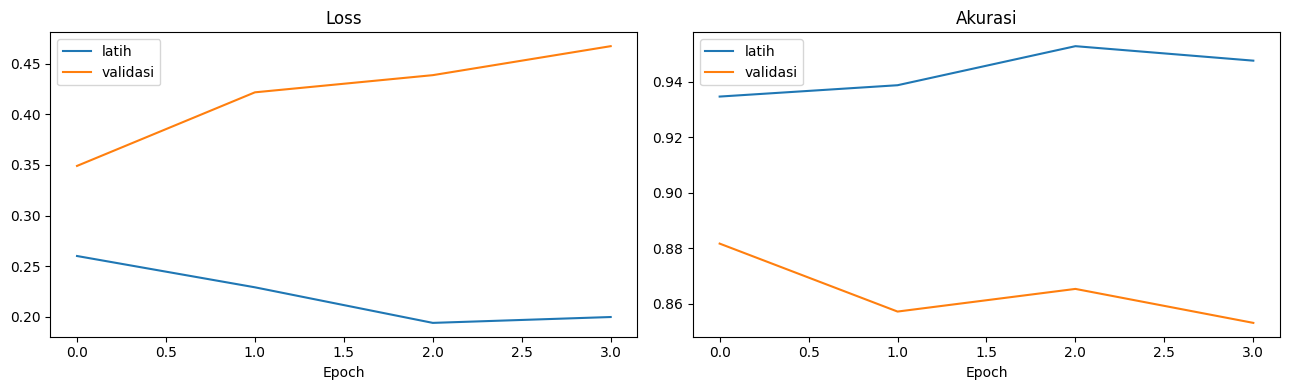

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(riwayat.history['loss'], label='latih')
axes[0].plot(riwayat.history['val_loss'], label='validasi')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(riwayat.history['accuracy'], label='latih')
axes[1].plot(riwayat.history['val_accuracy'], label='validasi')
axes[1].set_title('Akurasi'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

### 9.3 Evaluasi
Model dievaluasi pada data latih dan data uji dengan ambang 0,5 (probabilitas di atas 0,5 dianggap positif). Data uji hanya dipakai sekali, setelah pelatihan selesai.

Akurasi latih : 0.9591
Akurasi uji   : 0.8709
Macro F1 uji  : 0.8171

Laporan klasifikasi (data uji):
              precision    recall  f1-score   support

     negatif      0.930     0.903     0.916       958
     positif      0.684     0.756     0.718       266

    accuracy                          0.871      1224
   macro avg      0.807     0.829     0.817      1224
weighted avg      0.877     0.871     0.873      1224



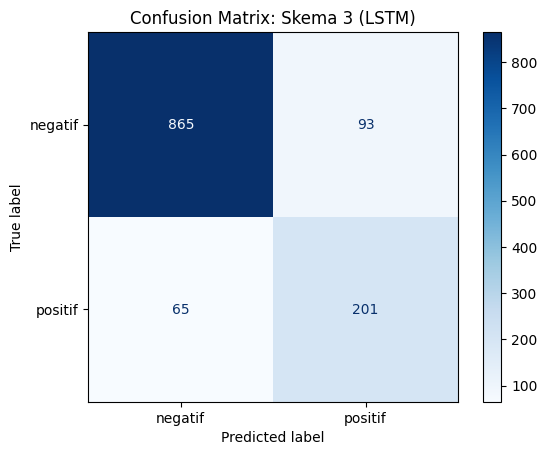

In [ ]:
pred_train_s3 = (model_lstm.predict(X_tr_seq, verbose=0) > 0.5).astype(int).ravel()
pred_test_s3 = (model_lstm.predict(X_test_seq, verbose=0) > 0.5).astype(int).ravel()

acc_train_s3 = accuracy_score(y_tr_num, pred_train_s3)
acc_test_s3 = accuracy_score(y_test_num, pred_test_s3)
f1_test_s3 = f1_score(y_test_num, pred_test_s3, average='macro')

print(f'Akurasi latih : {acc_train_s3:.4f}')
print(f'Akurasi uji   : {acc_test_s3:.4f}')
print(f'Macro F1 uji  : {f1_test_s3:.4f}')
print('\nLaporan klasifikasi (data uji):')
print(classification_report(y_test_num, pred_test_s3, target_names=['negatif', 'positif'], digits=3))

hasil_skema['Skema 3'] = {'train': acc_train_s3, 'test': acc_test_s3, 'macro_f1': f1_test_s3}

ConfusionMatrixDisplay.from_predictions(y_test_num, pred_test_s3,
                                        display_labels=['negatif', 'positif'], cmap='Blues')
plt.title('Confusion Matrix: Skema 3 (LSTM)')
plt.show()

## 10. Inference
Ketiga model digunakan untuk memprediksi sentimen ulasan baru yang tidak ada di data latih maupun data uji. Setiap ulasan baru melewati preprocessing yang sama dengan data latih, kemudian diubah menjadi fitur sesuai skema masing-masing (TF-IDF untuk skema 1 dan 2, urutan token dengan padding untuk skema 3). Keluaran berupa kelas sentimen: negatif atau positif.

Daftar ulasan uji mencakup ulasan yang jelas positif, jelas negatif, memakai bahasa tidak baku, memakai negasi, dan satu ulasan campuran untuk melihat perilaku model pada kasus yang ambigu.

In [ ]:
def preprocess_baru(teks):
    t = casefoldingText(teks)
    t = cleaningText(t)
    t = normalisasiHurufBerulang(t)
    t = fix_slangwords(t)
    token = filteringText(tokenizingText(t))
    token = [stem_kata(w) for w in token]
    return ' '.join(token)


def prediksi_semua(ulasan):
    bersih = preprocess_baru(ulasan)
    if bersih.strip() == '':
        return {'Skema 1 (LR)': '-', 'Skema 2 (SVM)': '-', 'Skema 3 (LSTM)': '-'}

    # Skema 1 dan 2: TF-IDF
    p1 = lr.predict(tfidf_s1.transform([bersih]))[0]
    p2 = svm.predict(tfidf_s2.transform([bersih]))[0]

    # Skema 3: tokenisasi, padding, lalu ambang 0,5
    seq = pad_sequences(tokenizer.texts_to_sequences([bersih]),
                        maxlen=MAXLEN, padding='post', truncating='post')
    prob = model_lstm.predict(seq, verbose=0)[0][0]
    p3 = 'positif' if prob > 0.5 else 'negatif'

    return {'Skema 1 (LR)': p1, 'Skema 2 (SVM)': p2, 'Skema 3 (LSTM)': p3}

In [ ]:
ulasan_uji = [
    "Aplikasinya bagus banget, transfer cepat dan mudah dipakai",
    "Sering error, tidak bisa login padahal data sudah benar",
    "Mantap, sangat membantu transaksi sehari-hari",
    "Lambat parah, mau transfer aja gagal terus",
    "Gk bisa dibuka, tolong diperbaiki secepatnya",
    "Fiturnya lengkap dan tampilannya simpel",
    "Tidak ada masalah sama sekali, puas banget",
    "Bagus sih tapi sering error pas transfer",       # ulasan campuran
]

baris = []
for u in ulasan_uji:
    hasil = prediksi_semua(u)
    sepakat = 'ya' if len(set(hasil.values())) == 1 else 'tidak'
    baris.append({'Ulasan': u[:60], **hasil, 'Sepakat': sepakat})

pd.DataFrame(baris)

,Ulasan,Skema 1 (LR),Skema 2 (SVM),Skema 3 (LSTM),Sepakat
0,"Aplikasinya bagus banget, transfer cepat dan m...",positif,positif,positif,ya
1,"Sering error, tidak bisa login padahal data su...",negatif,negatif,negatif,ya
2,"Mantap, sangat membantu transaksi sehari-hari",positif,positif,positif,ya
3,"Lambat parah, mau transfer aja gagal terus",negatif,negatif,negatif,ya
4,"Gk bisa dibuka, tolong diperbaiki secepatnya",negatif,negatif,negatif,ya
5,Fiturnya lengkap dan tampilannya simpel,positif,positif,positif,ya
6,"Tidak ada masalah sama sekali, puas banget",positif,negatif,positif,tidak
7,Bagus sih tapi sering error pas transfer,positif,negatif,positif,tidak


Dari delapan ulasan uji, ketiga model sepakat dan benar pada enam ulasan yang sentimennya jelas, termasuk ulasan berbahasa tidak baku ("Gk bisa dibuka"). Pada ulasan "Tidak ada masalah sama sekali, puas banget", model SVM memprediksi negatif padahal ulasan tersebut positif, kemungkinan karena kata "masalah" lebih kuat dikaitkan dengan kelas negatif pada data latih dibanding negasi yang mendahuluinya. Pada ulasan campuran ("Bagus sih tapi sering error pas transfer"), model memberi hasil berbeda karena sentimennya memang ambigu dan model dilatih pada ulasan dengan sentimen yang jelas. Jumlah ulasan uji kecil sehingga hasil ini hanya bersifat ilustratif.

## **Perbandingan Hasil**

In [ ]:
tabel = pd.DataFrame(hasil_skema).T.round(4)
tabel.columns = ['Akurasi latih', 'Akurasi uji', 'Macro F1 uji']
tabel['Selisih latih-uji'] = (tabel['Akurasi latih'] - tabel['Akurasi uji']).round(4)
tabel.insert(0, 'Algoritma', ['Logistic Regression', 'SVM (LinearSVC)', 'LSTM'])
tabel.insert(1, 'Fitur', ['TF-IDF', 'TF-IDF n-gram (1,2)', 'Embedding'])
tabel.insert(2, 'Split', ['80/20', '70/30', '80/20'])
tabel

,Algoritma,Fitur,Split,Akurasi latih,Akurasi uji,Macro F1 uji,Selisih latih-uji
Skema 1,Logistic Regression,TF-IDF,80/20,0.9083,0.8595,0.8097,0.0488
Skema 2,SVM (LinearSVC),"TF-IDF n-gram (1,2)",70/30,0.9680,0.8742,0.8216,0.0938
Skema 3,LSTM,Embedding,80/20,0.9591,0.8709,0.8171,0.0882


In [ ]:
!pip install pipreqs nbconvert -q

# Ubah notebook pelatihan jadi .py di folder sementara
!jupyter nbconvert --to script "/content/drive/MyDrive/Colab Notebooks/submission_sentimen_analisis/pelatihan_model_sentimen.ipynb" --output-dir=/content/reqs_pelatihan

# Buat requirements dari import yang ada (versi mengikuti yang terpasang)
!pipreqs /content/reqs_pelatihan --force --use-local
!cat /content/reqs_pelatihan/requirements.txt

  Preparing metadata (setup.py) ... done
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/submission_sentimen_analisis/pelatihan_model_sentimen.ipynb to script
[NbConvertApp] Writing 17780 bytes to /content/reqs_pelatihan/pelatihan_model_sentimen.txt
INFO: Successfully saved requirements file in /content/reqs_pelatihan/requirements.txt

